In [3]:
import pandas as pd
import re

In [4]:
df = pd.read_csv(r"D:\SA dataset\archive\IMDB Dataset.csv")

In [5]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [7]:
df.shape

(50000, 2)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [9]:
df["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

## Clean Text

In [10]:
def clean_text(text):
    text = re.sub(r'<.*?>', '',text)
    text = re.sub(r'[^a-zA-Z\s]', '',text)
    text = text.lower()
    text = text.strip()
    return text
df["review"] = df["review"].apply(clean_text)

In [11]:
df.head()

,review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically theres a family where a little boy j...,negative
4,petter matteis love in the time of money is a ...,positive


In [12]:
df["review"][0]

'one of the other reviewers has mentioned that after watching just  oz episode youll be hooked they are right as this is exactly what happened with methe first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not a show for the faint hearted or timid this show pulls no punches with regards to drugs sex or violence its is hardcore in the classic use of the wordit is called oz as that is the nickname given to the oswald maximum security state penitentary it focuses mainly on emerald city an experimental section of the prison where all the cells have glass fronts and face inwards so privacy is not high on the agenda em city is home to manyaryans muslims gangstas latinos christians italians irish and moreso scuffles death stares dodgy dealings and shady agreements are never far awayi would say the main appeal of the show is due to the fact that it goes where other shows wouldnt dare forget pretty picture

## Stopwords Removal

In [13]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
print(stop_words)

{'i', "i've", "aren't", 'shan', 'down', 'll', 'their', "wouldn't", "hadn't", 'is', 'over', 'now', 'm', 'yours', 'himself', "shan't", 'on', 'whom', 'it', 'how', 'few', 'my', 'haven', 'was', "couldn't", "he'd", 'herself', 'ours', 'we', 'under', 'of', "hasn't", 'y', "won't", 'where', 'having', 'while', "we'd", 'did', 'has', 'all', 'themselves', 'other', "needn't", 're', "she'd", "wasn't", 'which', 'nor', 'weren', 'myself', 'for', 'me', 'such', 'doesn', "don't", "he'll", 'into', 'an', 'mightn', 'itself', 'or', 'been', 'won', "they've", 'what', 'didn', 'from', 'you', 'ma', 'both', 'them', "mustn't", 'up', 'wasn', "didn't", 'she', 'if', 'am', 'these', 'too', 'theirs', 'more', "i'll", 'until', 'hers', "they'll", 'needn', "haven't", 'do', 'again', 'own', "isn't", 'but', 'off', 'above', 'as', 'wouldn', 'ain', 'her', 'does', 'mustn', 'there', "you're", 'had', 'hadn', 'd', "we've", 'being', "should've", 'the', "she's", 'were', "we'll", 'between', 'most', "it'll", 'out', 'some', "you'd", 'those', 

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\subha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [14]:
def remove_stopwords(text):
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return " ".join(words)

In [15]:
df["review"][0]

'one of the other reviewers has mentioned that after watching just  oz episode youll be hooked they are right as this is exactly what happened with methe first thing that struck me about oz was its brutality and unflinching scenes of violence which set in right from the word go trust me this is not a show for the faint hearted or timid this show pulls no punches with regards to drugs sex or violence its is hardcore in the classic use of the wordit is called oz as that is the nickname given to the oswald maximum security state penitentary it focuses mainly on emerald city an experimental section of the prison where all the cells have glass fronts and face inwards so privacy is not high on the agenda em city is home to manyaryans muslims gangstas latinos christians italians irish and moreso scuffles death stares dodgy dealings and shady agreements are never far awayi would say the main appeal of the show is due to the fact that it goes where other shows wouldnt dare forget pretty picture

In [16]:
df["sentiment"] = df["sentiment"].map({'positive':1 , 'negative':0})
df["sentiment"].value_counts()

sentiment
1    25000
0    25000
Name: count, dtype: int64

## Train,Test,Split

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
x = df["review"]
y = df["sentiment"]

x_train , x_test , y_train , y_test = train_test_split(x , y,test_size=0.2,random_state=42)
print(x_train.shape)
print(x_test.shape)

(40000,)
(10000,)


In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [20]:
tfidf = TfidfVectorizer(max_features=5000)
x_train = tfidf.fit_transform(x_train)
x_test = tfidf.transform(x_test)

print(x_train.shape)

(40000, 5000)


## Model Trainin

In [21]:
from sklearn.linear_model import LogisticRegression

In [22]:
model = LogisticRegression()
model.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [23]:
df["sentiment"].isnull().sum()

np.int64(0)

In [24]:
df = df.dropna(subset = ["sentiment"])
print(df.shape)

(50000, 2)


In [25]:
df["sentiment"].unique()

array([1, 0])

In [26]:
df.head()

,review,sentiment
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production the filming tech...,1
2,i thought this was a wonderful way to spend ti...,1
3,basically theres a family where a little boy j...,0
4,petter matteis love in the time of money is a ...,1


In [27]:
df2 = pd.read_csv(r"D:\SA dataset\archive\IMDB Dataset.csv")
print(df2.head())
print(df2.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)


In [28]:
import pandas as pd
import re
import nltk

nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Load fresh
df = pd.read_csv(r"D:\SA dataset\archive\IMDB Dataset.csv")

# Clean text
def clean_text(text):
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower()
    text = text.strip()
    return text

# Remove stopwords
def remove_stopwords(text):
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return " ".join(words)

df["review"] = df["review"].apply(clean_text)
df["review"] = df["review"].apply(remove_stopwords)

# Encoding
df["sentiment"] = df["sentiment"].map({"positive": 1, "negative": 0})

# Check karo
print(df["sentiment"].value_counts())
print(df.shape)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\subha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


sentiment
1    25000
0    25000
Name: count, dtype: int64
(50000, 2)


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

print(X_train.shape)
print(X_test.shape)

(40000, 5000)
(10000, 5000)


In [30]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [31]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.8876


In [32]:
review = ["this movie was absolutely amazing and i loved it"]

review_clean = tfidf.transform(review)
prediction = model.predict(review_clean)

if prediction[0] == 1:
    print("Positive 😄")
else:
    print("Negative 😞")

Positive 😄


In [33]:
review = ["this movie was terrible and complete waste of time"]

review_clean = tfidf.transform(review)
prediction = model.predict(review_clean)

if prediction[0] == 1:
    print("Positive 😄")
else:
    print("Negative 😞")

Negative 😞


In [34]:
import pickle

pickle.dump(model, open("model.pkl", "wb"))
pickle.dump(tfidf, open("tfidf.pkl", "wb"))

In [35]:
pip show scikit-learn

Name: scikit-learnNote: you may need to restart the kernel to use updated packages.

Version: 1.9.0
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License: 
Location: D:\Anaconda\Lib\site-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: imbalanced-learn


In [36]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[4333  628]
 [ 496 4543]]


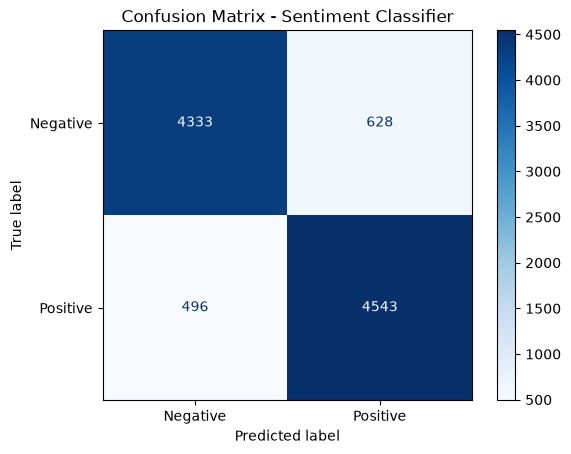

In [37]:
# Confusion Matrix Heatmap
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Sentiment Classifier")
plt.show()

In [38]:
# Classification Report (Precision, Recall, F1-score)
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

              precision    recall  f1-score   support

    Negative       0.90      0.87      0.89      4961
    Positive       0.88      0.90      0.89      5039

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [41]:
import pickle

pickle.dump(model, open("model.pkl", "wb"))
pickle.dump(tfidf, open("tfidf.pkl", "wb"))

In [42]:
pip show scikit-learn

Name: scikit-learn
Version: 1.9.0
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License: 
Location: D:\Anaconda\Lib\site-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: imbalanced-learn
Note: you may need to restart the kernel to use updated packages.


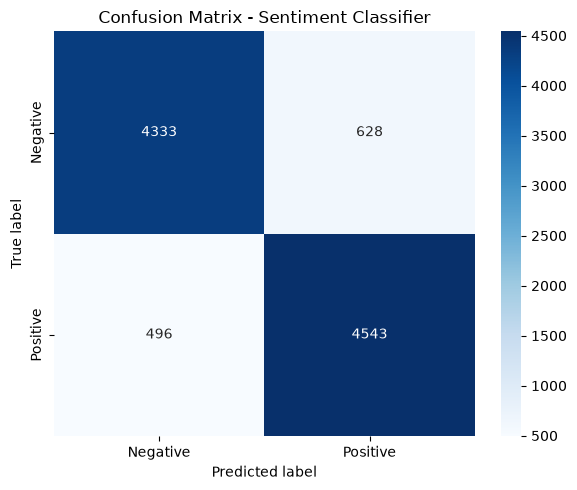

Accuracy       : 88.76%
Positive class : precision=87.86%  recall=90.16%  f1=88.99%
Negative class : precision=89.73%  recall=87.34%  f1=88.52%


In [1]:
"""
Generates the Confusion Matrix diagram for the Movie Sentiment Analyzer
using seaborn. Run this after evaluating the model on the test set.
"""

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ---------------------------------------------------------------
# Option A: if you already have y_test (true labels) and y_pred
# (model predictions) from your training notebook, just use them
# directly instead of the hard-coded example below:
#
#   y_pred = model.predict(X_test_tfidf)
#   cm = confusion_matrix(y_test, y_pred)
#
# Option B: if you only have the counts (as already computed),
# build the matrix directly like this:
# ---------------------------------------------------------------

cm = [[4333, 628],   # True Negative, False Positive
      [496, 4543]]   # False Negative, True Positive

labels = ["Negative", "Positive"]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
)
plt.title("Confusion Matrix - Sentiment Classifier")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

# ---------------------------------------------------------------
# Precision / Recall / F1-score for each class, computed directly
# from the confusion matrix counts above.
# ---------------------------------------------------------------

tn, fp, fn, tp = cm[0][0], cm[0][1], cm[1][0], cm[1][1]
total = tn + fp + fn + tp

accuracy = (tp + tn) / total
precision_pos = tp / (tp + fp)
recall_pos = tp / (tp + fn)
f1_pos = 2 * precision_pos * recall_pos / (precision_pos + recall_pos)

precision_neg = tn / (tn + fn)
recall_neg = tn / (tn + fp)
f1_neg = 2 * precision_neg * recall_neg / (precision_neg + recall_neg)

print(f"Accuracy       : {accuracy * 100:.2f}%")
print(f"Positive class : precision={precision_pos*100:.2f}%  recall={recall_pos*100:.2f}%  f1={f1_pos*100:.2f}%")
print(f"Negative class : precision={precision_neg*100:.2f}%  recall={recall_neg*100:.2f}%  f1={f1_neg*100:.2f}%")

# If you have the actual y_test / y_pred arrays, this gives the same
# report in one line using scikit-learn instead of manual formulas:
# print(classification_report(y_test, y_pred, target_names=labels))